In [4]:
%pip install qutip matplotlib scipy

Note: you may need to restart the kernel to use updated packages.


In [41]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import *
from scipy.optimize import curve_fit

In [ ]:
#params
f_q = 5e9 #qubit frequency
omega_q = 2*np.pi*f_q #qubit angular frequency

alpha = 2*np.pi*(-200e6) #anharmonicity factor 

In [5]:
#two level qubit
N_q = 2 #dimension of two level

g = basis(N_q,0)
e1 = basis(N_q,1)

sx = sigmax()
sy = sigmay()
sz = sigmaz()

H_q = 0 * sz #resonant rotational frame hamiltonian


In [ ]:
#three level system
N_transmon = 3

g_3 = basis(N_transmon,0)
e1_3 = basis(N_transmon,1)
e2_3 = basis(N_transmon,2)

a = destroy(N_transmon) #annihilation operator
n = a.dag()*a #num operator
iden = qeye(N_transmon) #identity operator

H_transmon = (alpha * n*(n-iden))/2 #resonant rotational frame hamiltonian for 3 level system


In [15]:
states = [g_3, e1_3, e2_3]

for i, state in enumerate(states):
    energy = expect(H_transmon, state)
    print(f"State |{i}>: {energy/(2*np.pi*1e6):.2f} MHz")


State |0>: 0.00 MHz
State |1>: 0.00 MHz
State |2>: -200.00 MHz


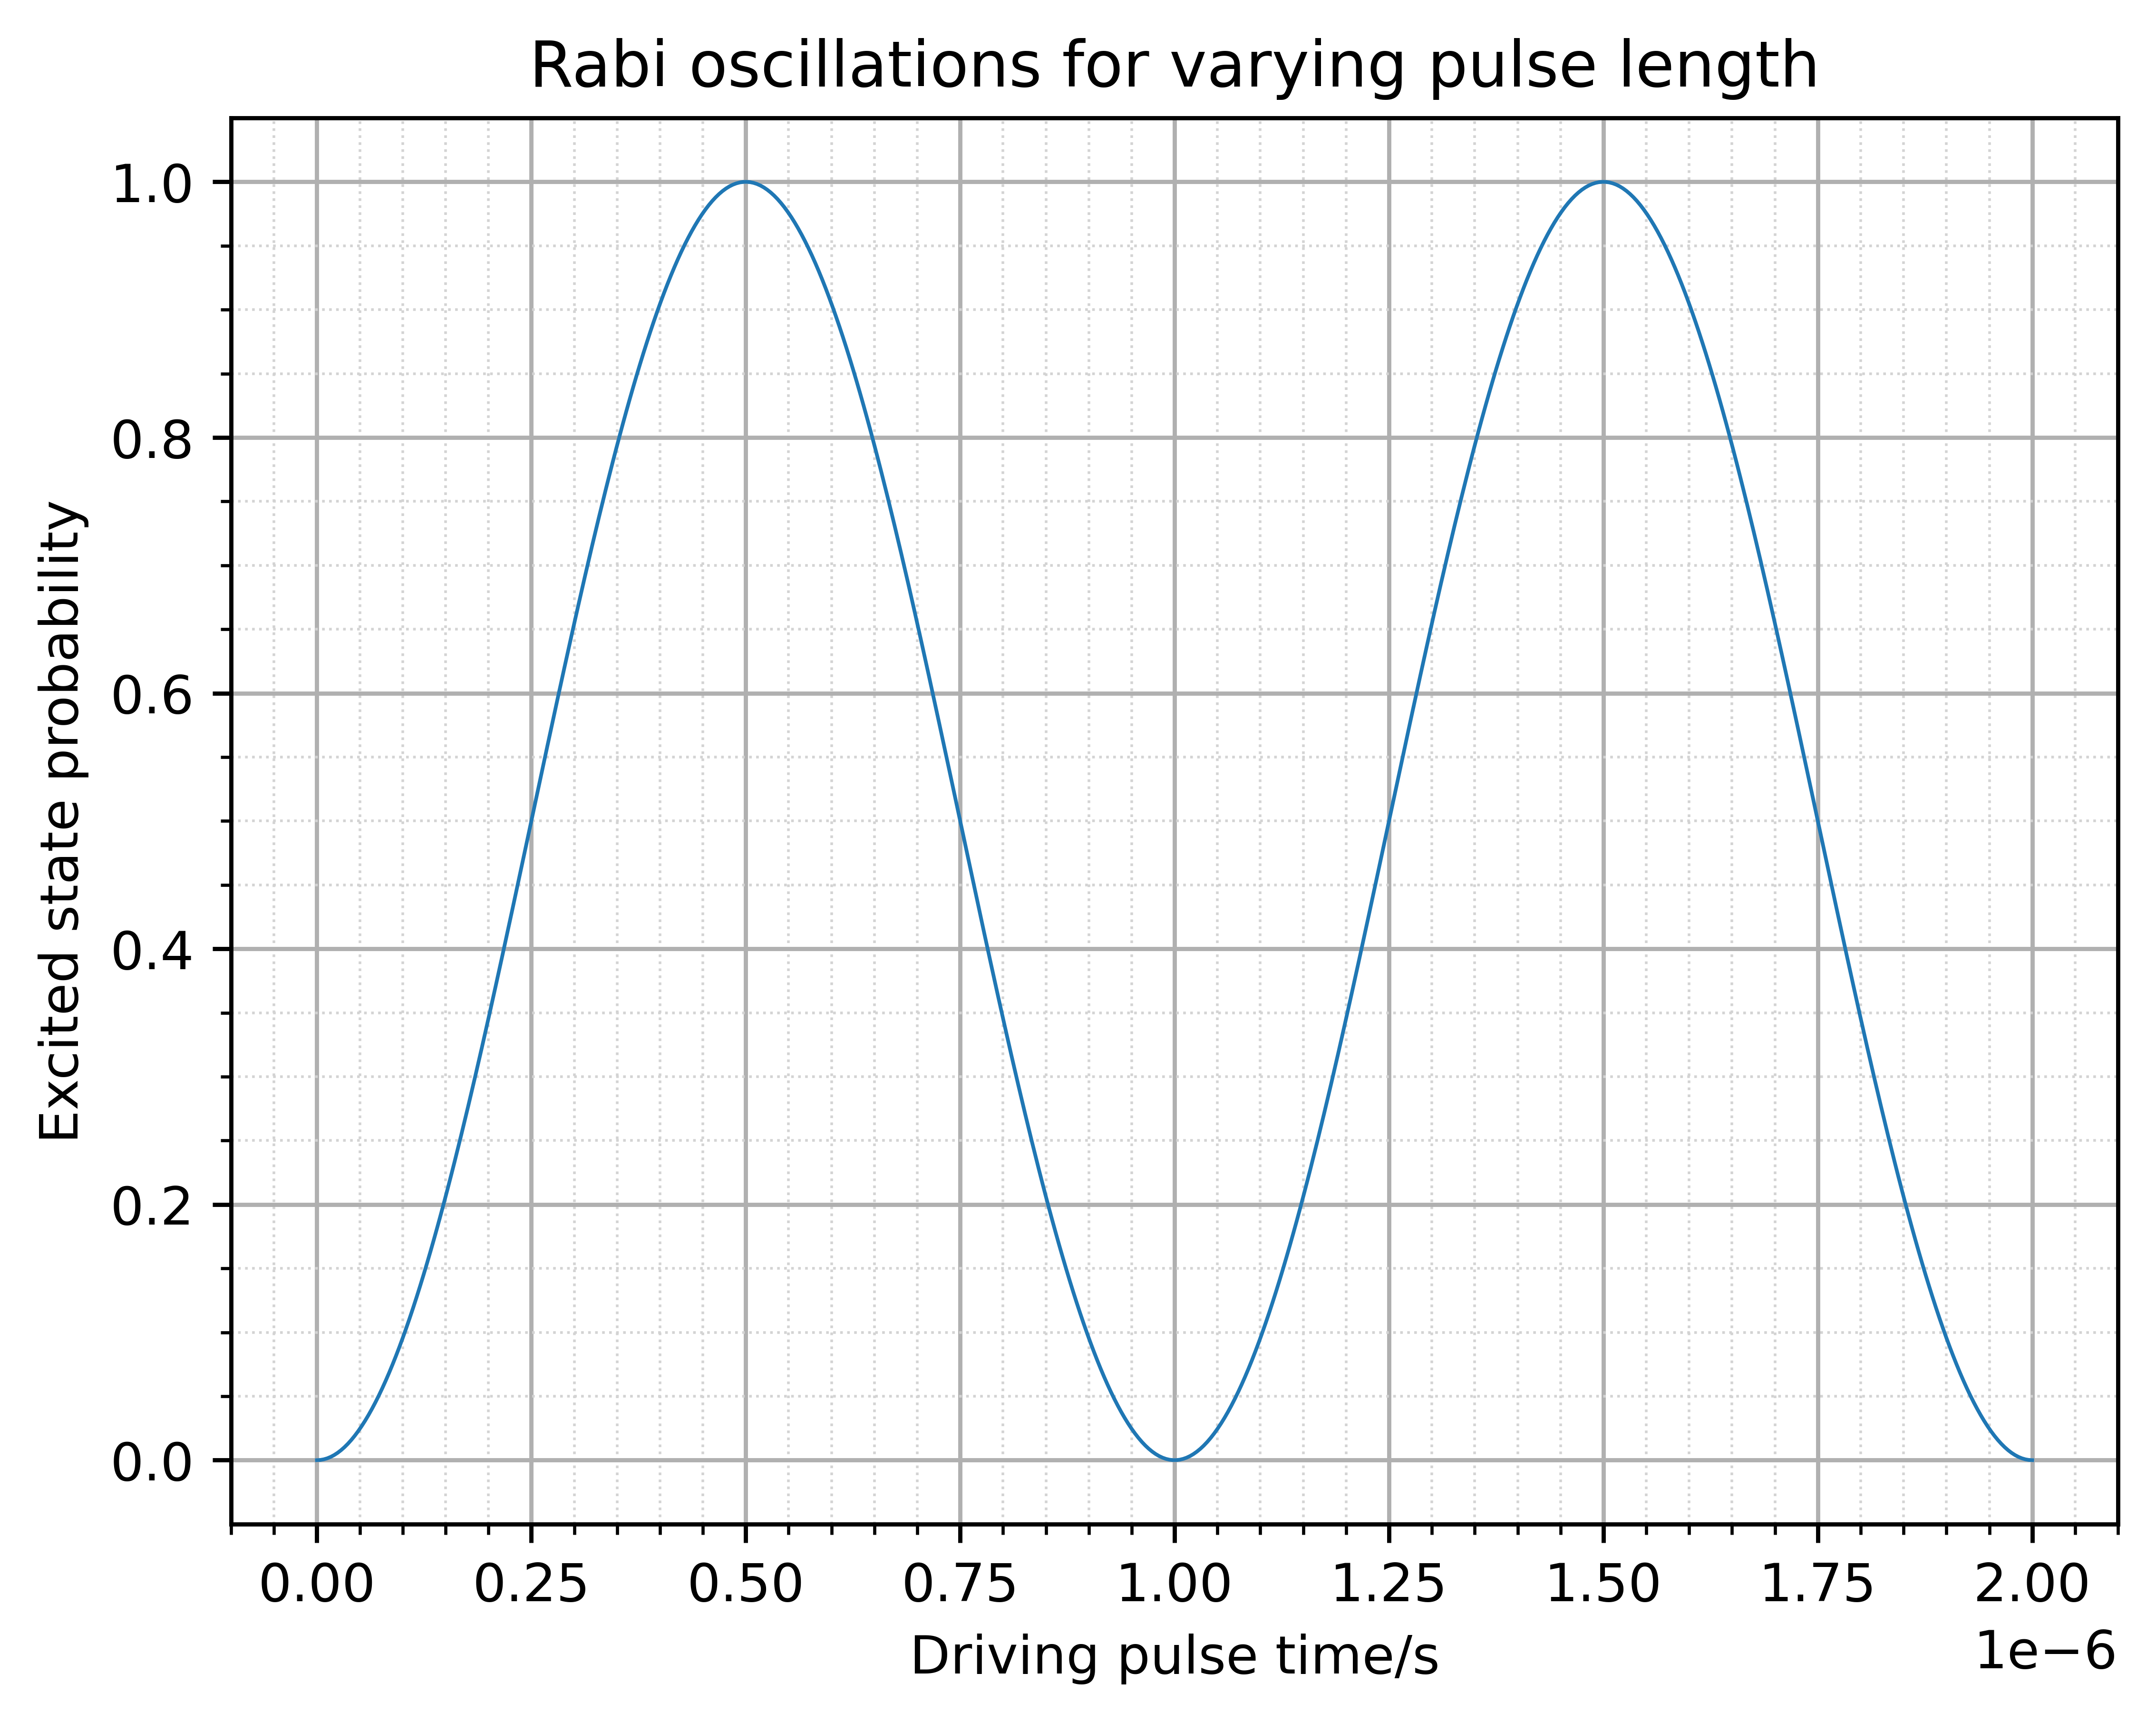

In [22]:
#Rabi oscillations
time = np.linspace(0,2e-6,500) #s
omega = 2*np.pi*1e6 #rad/s

H_drive = omega/2 *sx
P_excited = e1*e1.dag() #projection operator for excited state

output = mesolve(H_drive, g, time, c_ops=[], e_ops=[P_excited])

excited_prob = output.expect[0]

plt.figure(dpi=800)

plt.title('Rabi oscillations for varying pulse length')
plt.xlabel('Driving pulse time/s')
plt.ylabel('Excited state probability')
plt.plot(time, excited_prob, linewidth=0.7)
plt.grid(which='major',axis='both')
plt.grid(which='minor',axis='both',linestyle='dotted',linewidth=0.5,color='lightgrey')
plt.minorticks_on()

plt.show()

Calculated T1 = 49.9493 microseconds


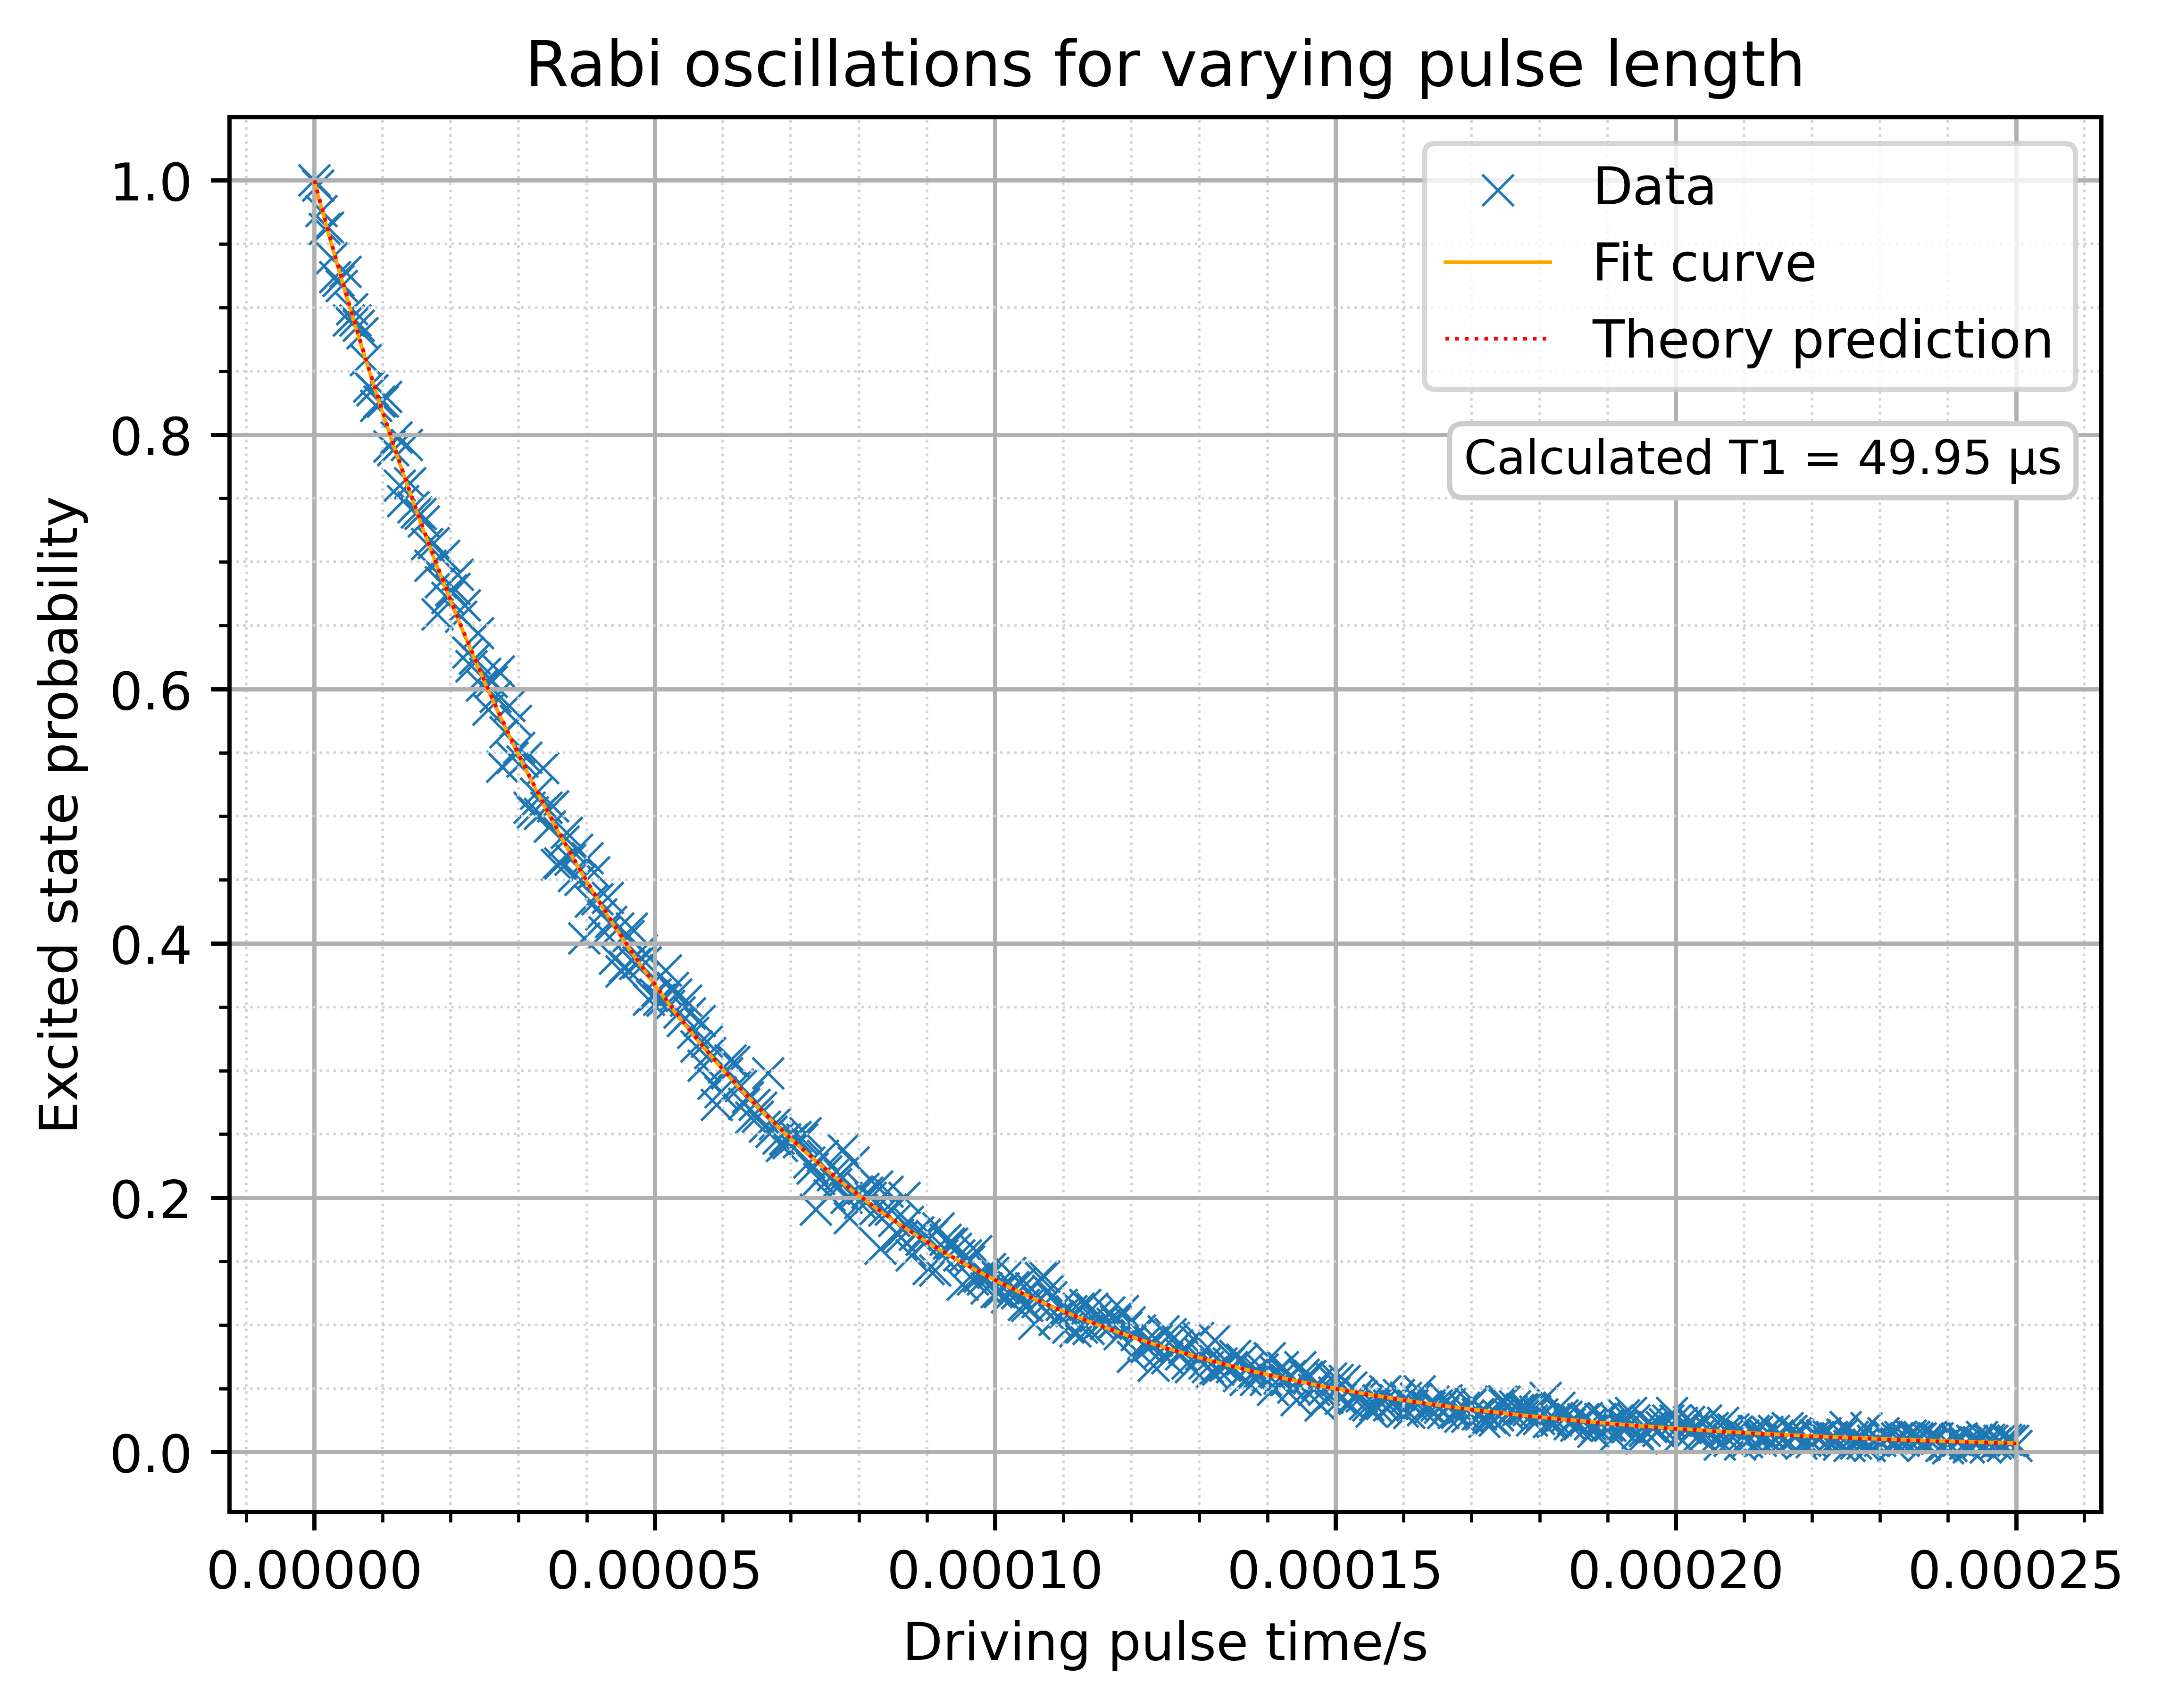

In [75]:
#T1 collapse operator
T1 = 50e-6 #s

time = np.linspace(0,250e-6,500) #s
omega = 2*np.pi*1e6 #rad/s

c1 = np.sqrt(1/T1)*g*e1.dag() # relaxation collapse operator
P_excited = e1*e1.dag() #projection operator for excited state

output = mesolve(H_q, e1, time, c_ops=[c1], e_ops=[P_excited])

excited_prob = output.expect[0]

shots = 1000
Prob = np.exp(-time/T1)
randomness = np.random.binomial(shots, Prob)/shots

def exponential(t, A, T1_fit, B):
    return A*np.exp(-t/T1_fit) + B

exp_fit, cov = curve_fit(exponential, xdata=time, ydata=randomness, p0=[1,50e-6,0])
T1_fit = exp_fit[1]
fitted = exponential(time, exp_fit[0], exp_fit[1], exp_fit[2])

print(f'Calculated T1 = {T1_fit*1e6:.4f} microseconds')

plt.figure(dpi=800)

plt.scatter(time, randomness , marker='x', linewidths=0.5, label='Data')
plt.plot(time, fitted, linewidth=0.7, color='orange', label='Fit curve')
plt.plot(time, excited_prob, linewidth=0.7, color='red', linestyle=':', label='Theory prediction')

plt.legend(loc='upper right')
plt.text(
    0.979, 0.77,
    f"Calculated T1 = {T1_fit*1e6:.2f} µs",
    transform=plt.gca().transAxes,
    fontsize=9,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(
        facecolor='white',
        edgecolor='0.8',
        boxstyle='round',
        alpha=1
    )
)

plt.title('Rabi oscillations for varying pulse length')
plt.xlabel('Driving pulse time/s')
plt.ylabel('Excited state probability')

plt.grid(which='major',axis='both')
plt.grid(which='minor',axis='both',linestyle='dotted',linewidth=0.5,color='lightgrey')
plt.minorticks_on()

plt.show()